# 01 — Liu, Stambaugh & Yuan (2019), "Size and value in China"

Replication on CSMAR (lighthouse.md section 5.1). This notebook only calls `src/` functions; all logic lives in
`src/replication/lsy/`. Every number is compared with the paper under the lighthouse 3.3 tolerances
(`src/replication/common/compare.py`); misses link to `docs/deviation_log.md`.

Rebuild everything from the terminal: `python -m csmar.build && python -m replication.lsy`.

In [1]:
import pandas as pd
from IPython.display import Image, display
from replication.lsy import tables as T
from replication.common.compare import compare
pd.set_option("display.width", 200, "display.max_rows", 400, "display.precision", 3)
segs = T.lsy_segments()
orig = segs["original"]
print({k: str(v) for k, v in segs.items()})

{'original': 'original 2000-01..2016-12', 'extended': 'extended 2017-01..2026-09', 'full': 'full 2000-01..2026-09'}


## Factor series vs Stambaugh's website (lighthouse 3.3: correlation ≥ 0.95, 2000-01..2021-12)

In [2]:
fc = T.factor_series_check()
fc.pivot(index="row", columns="col", values="value")

col,corr,mean_ours_pct,mean_web_pct,n_months
row,,,,
CH-3 mkt,0.999,0.680,0.662,264.0
CH-3 rf,1.000,0.189,0.189,264.0
CH-3 smb,0.993,0.662,0.677,264.0
CH-3 vmg,0.981,1.176,1.187,264.0
CH-4 mkt,0.999,0.680,0.662,264.0
CH-4 pmo,0.981,0.799,0.804,264.0
CH-4 rf,0.999,0.189,0.189,264.0
CH-4 smb,0.997,0.466,0.515,264.0
CH-4 vmg,0.986,1.176,1.097,264.0


## Paper vs ours, original period (2000-01..2016-12)

In [3]:
from replication.lsy.__main__ import figures  # also writes results/lsy/figures/
from replication.lsy import text_numbers as X
ours = pd.concat([T.table1(orig), T.table2(orig), T.table3(orig), T.table4(orig), T.section52(orig), T.table5(orig),
                  T.table6(orig), T.table7(orig), T.table8(orig), T.table9(orig), T.table10(orig), fc, X.all_text(orig), figures("original")], ignore_index=True)
cmp = compare("lsy", ours)
scored = cmp[cmp["pass"].notna()]
summary = scored.groupby("table")["pass"].agg(passed=lambda s: int((s == True).sum()), scored="size")
summary.loc["TOTAL"] = summary.sum()
summary

STK_MA_TRADINGMAIN: _2012_2016/STK_MA_TRADINGMAIN.csv data row 20072 has an unescaped quote inside a field (kept verbatim): ['200000041870', '300230']


STK_MA_TRADINGMAIN: _2012_2016/STK_MA_TRADINGMAIN.csv data row 30920 has an unescaped quote inside a field (kept verbatim): ['210000010775', '600699']


STK_MA_TRADINGMAIN: _2012_2016/STK_MA_TRADINGMAIN.csv data row 30930 has an unescaped quote inside a field (kept verbatim): ['200000037142', '600699']


STK_MA_TRADINGMAIN: _2017_2021/STK_MA_TRADINGMAIN.csv data row 38597 has an unescaped quote inside a field (kept verbatim): ['210000050936', '600783']


STK_MA_TRADINGMAIN: _2022_2026/STK_MA_TRADINGMAIN.csv data row 1702 has an unescaped quote inside a field (kept verbatim): ['260000158748', '000656']


,passed,scored
table,,
F1,0,2
F2,0,1
S5.2,5,6
T1,18,18
T10,154,187
T2,68,80
T3,17,18
T4,8,8
T5,10,10


In [4]:
def show(table):
    x = cmp[cmp["table"] == table][["row", "col", "paper", "ours", "kind", "pass"]].copy()
    x["pass"] = x["pass"].map({True: "ok", False: "MISS", None: "-"}).fillna("-")
    return x.reset_index(drop=True)
show("T3")

,row,col,paper,ours,kind,pass
0,MKT,mean,0.66,0.723,pct_return,ok
1,SMB,mean,1.03,0.983,pct_return,ok
2,VMG,mean,1.14,1.184,pct_return,ok
3,MKT,std,8.09,8.183,pct_std,ok
4,SMB,std,4.52,4.502,pct_std,ok
5,VMG,std,3.75,3.739,pct_std,ok
6,MKT,t,1.16,1.262,t,ok
7,SMB,t,3.25,3.119,t,ok
8,VMG,t,4.34,4.522,t,ok
9,MKT,corr_SMB,0.12,0.144,coef,ok


In [5]:
show('T1')

,row,col,paper,ours,kind,pass
0,A:b,Smallest,0.14,0.177,coef,ok
1,A:b,Middle,0.17,0.241,coef,ok
2,A:b,Largest,0.24,0.272,coef,ok
3,A:t(b),Smallest,6.34,8.216,t,ok
4,A:t(b),Middle,12.42,14.742,t,ok
5,A:t(b),Largest,17.28,18.292,t,ok
6,A:R2_pct,Smallest,0.30,0.364,share_pct,ok
7,A:R2_pct,Middle,1.00,0.789,share_pct,ok
8,A:R2_pct,Largest,1.70,1.442,share_pct,ok
9,B:b,Smallest,0.43,0.580,coef,ok


In [6]:
show('T2')

,row,col,paper,ours,kind,pass
0,Intercept,(1),1.490e-02,1.282e-02,coef,ok
1,t(Intercept),(1),1.940e+00,1.677e+00,t,ok
2,beta,(1),-2.000e-04,1.116e-03,coef,MISS
3,t(beta),(1),-9.000e-02,4.320e-01,t,ok
4,R2,(1),1.960e-02,1.980e-02,info,-
5,Intercept,(2),5.810e-02,6.071e-02,coef,ok
6,t(Intercept),(2),3.320e+00,3.225e+00,t,ok
7,logME,(2),-4.900e-03,-5.075e-03,coef,ok
8,t(logME),(2),-2.910e+00,-2.868e+00,t,ok
9,R2,(2),2.770e-02,3.904e-02,info,-


In [7]:
show('T4')

,row,col,paper,ours,kind,pass
0,A:MKT,avg_R2_pct,38.5,40.128,share_pct,ok
1,"A:MKT, SMB",avg_R2_pct,50.7,52.601,share_pct,ok
2,"A:MKT, VMG",avg_R2_pct,47.1,49.705,share_pct,ok
3,"A:MKT, SMB, VMG",avg_R2_pct,53.6,55.252,share_pct,ok
4,B:MKT,avg_R2_pct,41.7,43.465,share_pct,ok
5,"B:MKT, SMB",avg_R2_pct,52.8,52.828,share_pct,ok
6,"B:MKT, VMG",avg_R2_pct,50.1,51.148,share_pct,ok
7,"B:MKT, SMB, VMG",avg_R2_pct,56.2,55.581,share_pct,ok


In [8]:
pd.concat([show('S5.2'), show('T5')])

,row,col,paper,ours,kind,pass
0,SMB_with_shells,mean,1.360e+00,1.360e+00,pct_return,ok
1,VMG_with_shells,mean,8.700e-01,9.222e-01,pct_return,ok
2,SMB,alpha_vs_shell_factors,-2.300e-01,-2.483e-01,pct_return,ok
3,SMB,t_alpha_vs_shell_factors,-3.300e+00,-3.679e+00,t,ok
4,VMG,alpha_vs_shell_factors,2.700e-01,2.042e-01,pct_return,ok
5,VMG,t_alpha_vs_shell_factors,3.320e+00,2.469e+00,t,MISS
0,FFSMB,alpha_CH3,-4.000e-02,-4.058e-02,pct_return,ok
1,FFSMB,t_alpha_CH3,-6.600e-01,-5.929e-01,t,ok
2,FFHML,alpha_CH3,3.400e-01,2.647e-01,pct_return,ok
3,FFHML,t_alpha_CH3,9.700e-01,7.732e-01,t,ok


In [9]:
show('T6')

,row,col,paper,ours,kind,pass
0,A:size,Rbar,1.09,1.010,pct_return,ok
1,A:size,alpha,0.97,0.858,pct_return,MISS
2,A:size,beta,0.18,0.211,coef,ok
3,A:size,t(Rbar),1.92,1.785,t,ok
4,A:size,t(alpha),1.81,1.630,t,ok
5,A:size,t(beta),1.90,2.348,t,MISS
6,A:ep,Rbar,1.27,1.326,pct_return,ok
7,A:ep,alpha,1.37,1.444,pct_return,ok
8,A:ep,beta,-0.16,-0.163,coef,ok
9,A:ep,t(Rbar),2.58,2.670,t,ok


In [10]:
show('T7')

,row,col,paper,ours,kind,pass
0,A:size,alpha,0.21,0.240,pct_return,ok
1,A:size,b_mkt,0.01,0.018,coef,ok
2,A:size,b_smb,1.45,1.440,coef,ok
3,A:size,b_vmg,-0.54,-0.556,coef,ok
4,A:size,t(alpha),1.71,1.970,t,MISS
5,A:size,t(b_mkt),0.77,1.115,t,ok
6,A:size,t(b_smb),40.88,36.939,t,ok
7,A:size,t(b_vmg),-11.70,-11.265,t,ok
8,A:ep,alpha,0.04,0.023,pct_return,ok
9,A:ep,b_mkt,0.04,0.069,coef,ok


In [11]:
show('T8')

,row,col,paper,ours,kind,pass
0,A:size,alpha,0.16,0.139,pct_return,ok
1,A:size,b_mkt,0.04,0.048,coef,ok
2,A:size,b_smb,1.55,1.549,coef,ok
3,A:size,b_hml,-0.11,-0.118,coef,ok
4,A:size,t(alpha),1.36,1.189,t,ok
5,A:size,t(b_mkt),1.86,2.192,t,MISS
6,A:size,t(b_smb),34.29,34.179,t,ok
7,A:size,t(b_hml),-2.43,-2.547,t,ok
8,A:ep,alpha,1.54,1.563,pct_return,ok
9,A:ep,b_mkt,-0.07,-0.064,coef,ok


In [12]:
show('T9')

,row,col,paper,ours,kind,pass
0,A:avg_abs_alpha,Unadjusted,9.400e-01,8.598e-01,pct_return,ok
1,A:avg_abs_alpha,CAPM,1.020e+00,9.365e-01,pct_return,ok
2,A:avg_abs_alpha,FF-3,9.000e-01,8.475e-01,pct_return,ok
3,A:avg_abs_alpha,CH-3,4.500e-01,4.316e-01,pct_return,ok
4,A:avg_abs_t,Unadjusted,1.890e+00,1.687e+00,t,ok
5,A:avg_abs_t,CAPM,2.210e+00,1.959e+00,t,MISS
6,A:avg_abs_t,FF-3,2.700e+00,2.612e+00,t,ok
7,A:avg_abs_t,CH-3,1.120e+00,1.206e+00,t,ok
8,A:GRS10,Unadjusted,7.300e+00,7.397e+00,info,-
9,A:GRS10,CAPM,7.310e+00,7.393e+00,info,-


In [13]:
show('T10')

,row,col,paper,ours,kind,pass
0,A:size,alpha,0.23,3.690e-01,pct_return,MISS
1,A:size,b_mkt,0.05,2.979e-02,coef,ok
2,A:size,b_smb,1.50,1.428e+00,coef,ok
3,A:size,b_vmg,-0.42,-4.498e-01,coef,ok
4,A:size,b_pmo,0.01,3.465e-02,coef,ok
5,A:size,t(alpha),1.41,2.569e+00,t,MISS
6,A:size,t(b_mkt),3.05,1.923e+00,t,MISS
7,A:size,t(b_smb),39.38,4.086e+01,t,ok
8,A:size,t(b_vmg),-6.88,-8.670e+00,t,ok
9,A:size,t(b_pmo),0.17,5.415e-01,t,ok


## Numbers quoted in the text (sections 3–7), incl. the Table 10 CH-4 summary (section 7.2)

Items that cannot be produced from our data are listed as info rows with the reason in `targets/lsy_targets.csv`.

In [14]:
show('TXT')

,row,col,paper,ours,kind,pass
0,S4:corr_slopes_logME_EP+_col6,value,4.200e-01,0.286,coef,ok
1,S4:one_sd_EP+_effect_col8,pct_per_month,5.200e-01,0.575,pct_return,ok
2,S5.1:negEP_slope_on_positive_VMG,b,-2.800e-01,-0.330,coef,ok
3,S5.1:negEP_slope_on_positive_VMG,t,-3.310e+00,-4.209,t,ok
4,S5.1:negEP_share_of_universe,pct,1.500e+01,15.024,share_pct,ok
5,S5.2:bottom30_share_of_market_cap,pct,7.000e+00,7.097,share_pct,ok
6,S5.3:GRS_CH3_on_FF5_nonmarket,p,8.800e-01,0.314,pvalue,ok
7,S5.3:GRS_FF5_on_SMB_VMG,p,3.000e-04,0.713,pvalue,MISS
8,S6.1:universe_stocks_first_month,n,6.100e+02,607.000,count,ok
9,S6.1:universe_stocks_last_month,n,1.872e+03,1795.000,count,MISS


## Figures 1–2 (reverse-merger shells; identification rule in `src/replication/lsy/shells.py`, user acceptance item)

Produced by `python -m replication.lsy` into `results/lsy/figures/`. Deviation: docs/deviation_log.md LSY-6.

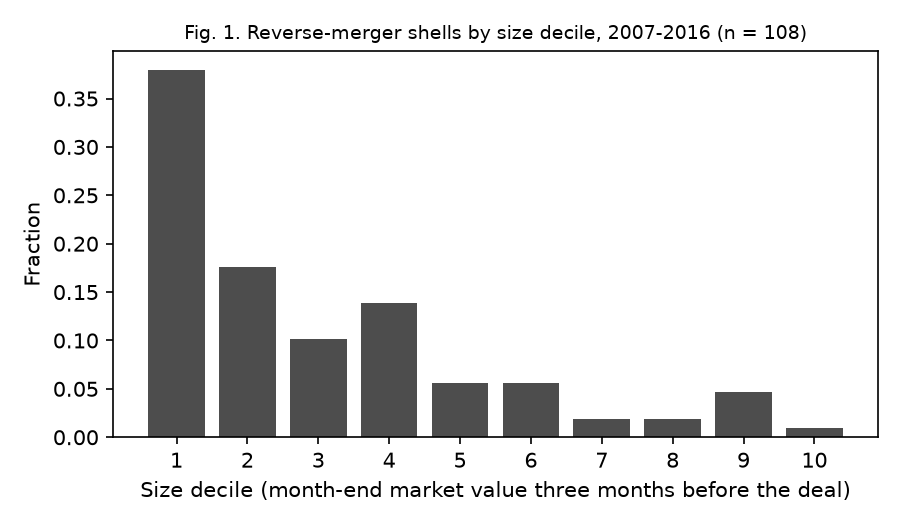

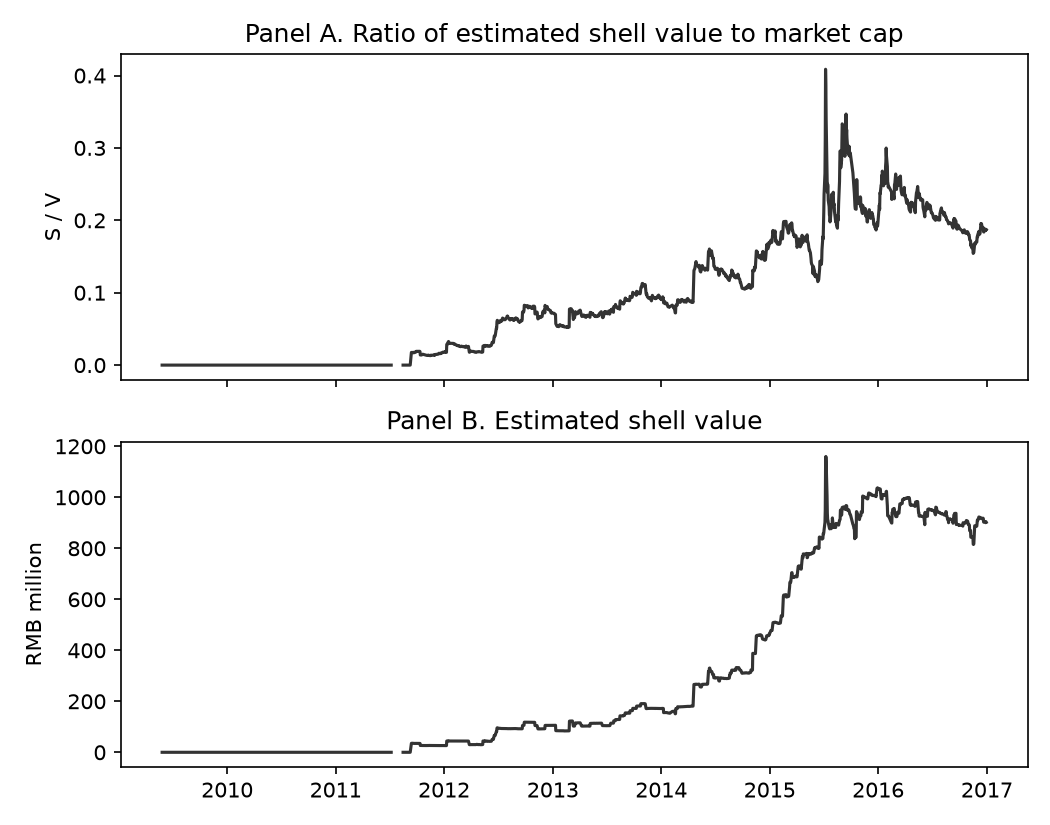

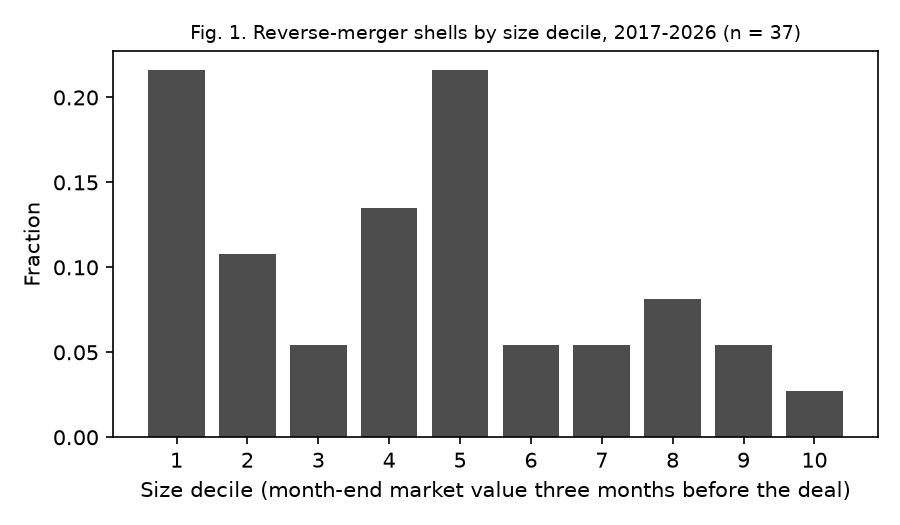

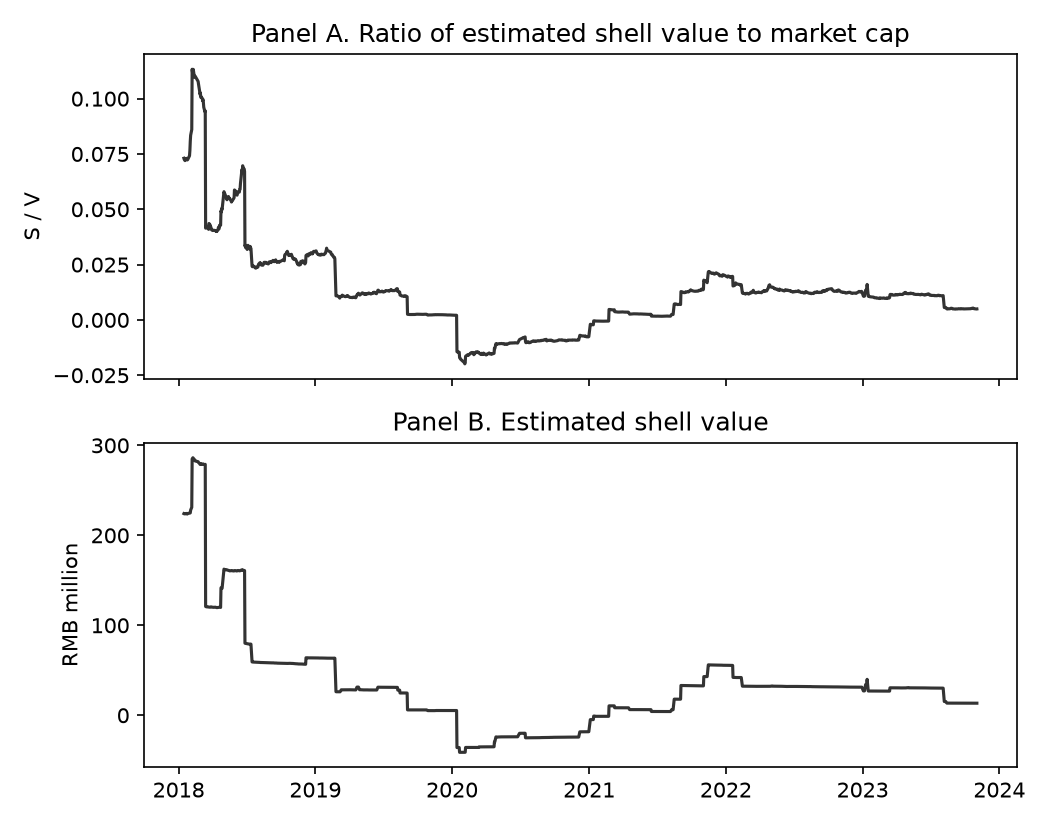

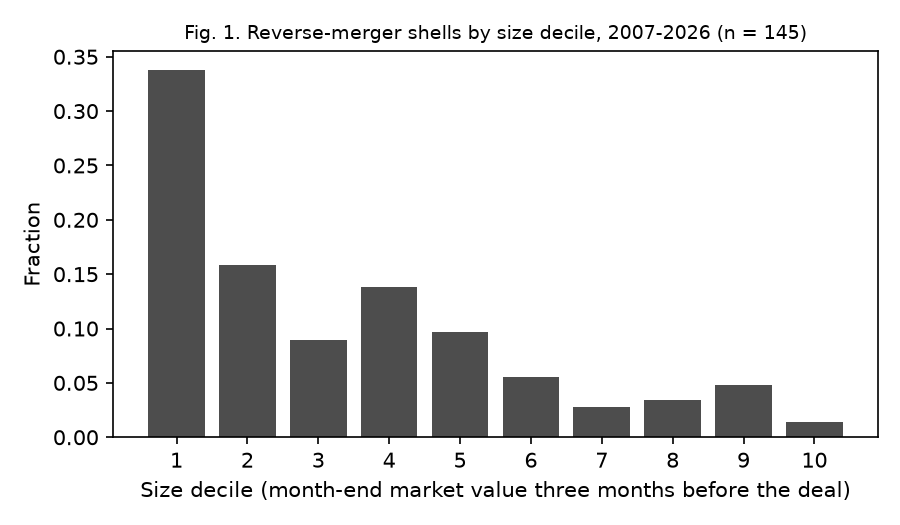

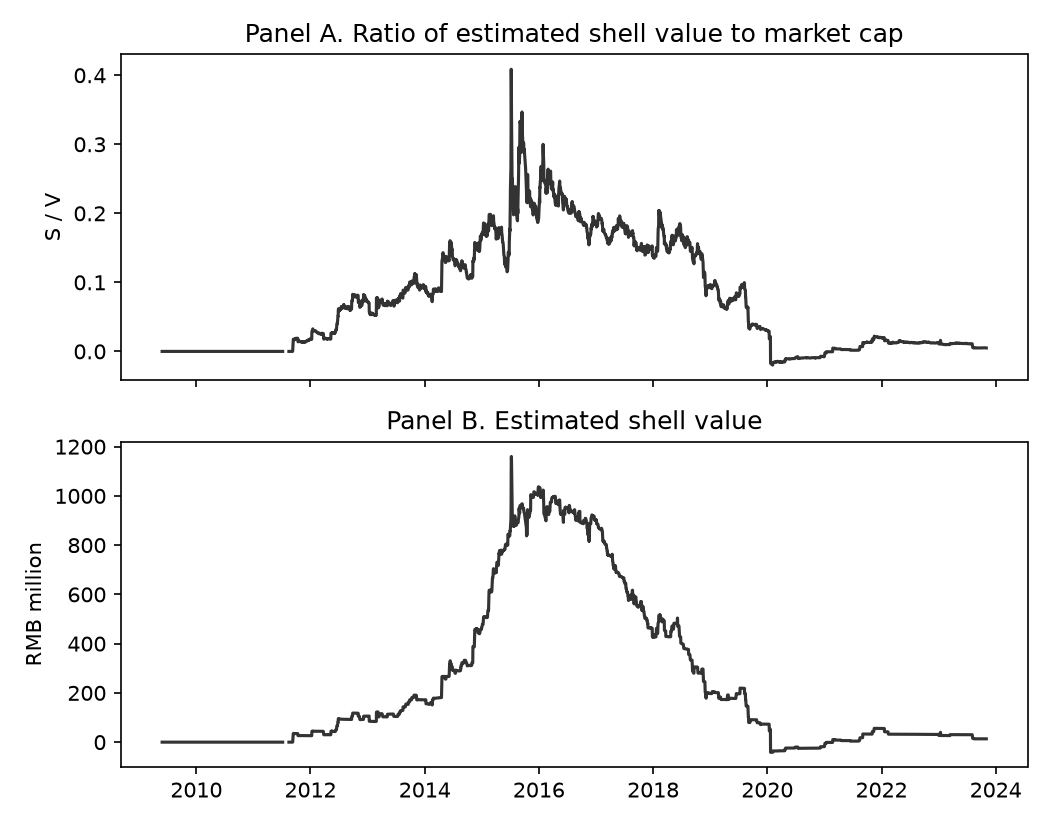

(      row                 col  paper     ours       kind  pass
 0   deals                   n  133.0  108.000      count  MISS
 1  shells  share_bottom30_pct   83.0   65.741  share_pct  MISS
 2  shells  share_bottom10_pct   50.0   37.963       info     -,
         row       col  paper   ours       kind  pass
 0  S_over_V  mean_pct   29.5  8.911  share_pct  MISS)

In [15]:
for f in [f"fig{k}_{n}_{s}.png" for s in ("original", "extended", "full") for k, n in ((1, "shell_size_deciles"), (2, "shell_value"))]:
    display(Image(filename=str(T.INTERIM.parents[1] / "results" / "lsy" / "figures" / f)))
show("F1"), show("F2")

## Extension to 2026 (lighthouse section 6)

Same functions, only the dates change. Does the paper's conclusion hold after 2016?

In [16]:
rows = []
for name, seg in segs.items():
    t3 = T.table3(seg).pivot(index="row", columns="col", values="value")
    for f in ["MKT", "SMB", "VMG"]:
        rows.append({"segment": str(seg), "factor": f, "mean_%": t3.loc[f, "mean"], "t": t3.loc[f, "t"]})
pd.DataFrame(rows).pivot(index="factor", columns="segment", values=["mean_%", "t"])

mean_%                                                                         t                                                
segment extended 2017-01..2026-09 full 2000-01..2026-09 original 2000-01..2016-12 extended 2017-01..2026-09 full 2000-01..2026-09 original 2000-01..2016-12
factor                                                                                                                                                     
MKT                         0.322                 0.577                     0.723                     0.735                 1.452                     1.262
SMB                         0.034                 0.637                     0.983                     0.099                 2.696                     3.119
VMG                         1.037                 1.130                     1.184                     2.602                 5.125                     4.522

In [17]:
t9 = {name: T.table9(seg).query("row == 'A:avg_abs_alpha'").set_index("col")["value"] for name, seg in segs.items()}
pd.DataFrame(t9).rename_axis("model: average |alpha| (unconditional sorts, % per month)")

,original,extended,full
"model: average |alpha| (unconditional sorts, % per month)",,,
Unadjusted,0.860,0.707,0.797
CAPM,0.936,0.862,0.889
FF-3,0.847,0.541,0.666
CH-3,0.432,0.635,0.560
